In [71]:
import numpy as np
import pandas as pd

In [72]:
courses = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Pandas/DF Merging ,Join ,Concat/Data sets/courses.csv')
month_1 = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Pandas/DF Merging ,Join ,Concat/Data sets/reg-month1.csv')
month_2 = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Pandas/DF Merging ,Join ,Concat/Data sets/reg-month2.csv')
std = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Pandas/DF Merging ,Join ,Concat/Data sets/students.csv')
matches = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Pandas/DF Merging ,Join ,Concat/Data sets/matches.csv')
deliveries = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Pandas/DF Merging ,Join ,Concat/Data sets/deliveries (1).csv')

In [73]:
# concat to join two or more data frames
regs = pd.concat([month_1 , month_2] , ignore_index=True)
regs

,student_id,course_id
0,23,1
1,15,5
2,18,6
3,23,4
4,16,9
5,18,1
6,1,1
7,7,8
8,22,3
9,15,1


In [74]:
regs2 =pd.concat([month_1 , month_2] , keys=['Nov' , 'Dec'])
type(regs2.loc[('Nov', 4)])
type(regs2.loc['Nov'])
regs2.loc['Nov'].iloc[:5]

,student_id,course_id
0,23,1
1,15,5
2,18,6
3,23,4
4,16,9


In [75]:
pd.concat([month_1 ,month_2 ] , axis=1)

,student_id,course_id,student_id,course_id
0,23.0,1.0,3,5
1,15.0,5.0,16,7
2,18.0,6.0,12,10
3,23.0,4.0,12,1
4,16.0,9.0,14,9
5,18.0,1.0,7,7
6,1.0,1.0,7,2
7,7.0,8.0,16,3
8,22.0,3.0,17,10
9,15.0,1.0,11,8


**Merge(Join)**
1. Inner Join
2. Left Join
3. Right Join
4. Outer Join

In [76]:
# inner 
std.tail(5)

,student_id,name,partner
20,21,Seema Kota,15
21,22,Yash Sethi,21
22,23,Chhavi Lachman,18
23,24,Radhika Suri,17
24,25,Shashank D’Alia,2


In [77]:
temp_df = pd.DataFrame({
     'student_id' :[26,27,28] ,
     'name' :['Khalid' , 'Hamza' , 'Kanwal'],
     'partner' : [27 ,25,26]
})

In [78]:
std = pd.concat([std,temp_df])
std.tail()

,student_id,name,partner
23,24,Radhika Suri,17
24,25,Shashank D’Alia,2
0,26,Khalid,27
1,27,Hamza,25
2,28,Kanwal,26


In [79]:
regs.tail()

,student_id,course_id
48,14,1
49,11,10
50,42,9
51,50,8
52,38,1


In [80]:
# inner join (only common)
std.merge(regs , how= 'inner' , on='student_id')

,student_id,name,partner,course_id
0,1,Kailash Harjo,23,1
1,1,Kailash Harjo,23,6
2,1,Kailash Harjo,23,10
3,1,Kailash Harjo,23,9
4,2,Esha Butala,1,5
5,3,Parveen Bhalla,3,3
6,3,Parveen Bhalla,3,5
7,7,Tarun Thaker,9,8
8,7,Tarun Thaker,9,10
9,7,Tarun Thaker,9,7


In [81]:
# left (common elements + left table elements )
std.merge(regs , how='left' , on= 'student_id').tail(7)

,student_id,name,partner,course_id
53,23,Chhavi Lachman,18,5.0
54,24,Radhika Suri,17,4.0
55,25,Shashank D’Alia,2,1.0
56,25,Shashank D’Alia,2,10.0
57,26,Khalid,27,NaN
58,27,Hamza,25,NaN
59,28,Kanwal,26,NaN


In [82]:
# right (common + right table elements that are not in left one also)
regs.merge(courses , how='right' , on='course_id').tail()

,student_id,course_id,course_name,price
50,17.0,10,pyspark,2499
51,1.0,10,pyspark,2499
52,11.0,10,pyspark,2499
53,NaN,11,Numpy,699
54,NaN,12,C++,1299


In [83]:
# outer (all elements from both tables)
regs.merge(std , how='outer' , on='student_id').tail(8)

,student_id,course_id,name,partner
55,25,1.0,Shashank D’Alia,2.0
56,25,10.0,Shashank D’Alia,2.0
57,26,NaN,Khalid,27.0
58,27,NaN,Hamza,25.0
59,28,NaN,Kanwal,26.0
60,38,1.0,NaN,NaN
61,42,9.0,NaN,NaN
62,50,8.0,NaN,NaN


# Q/A

In [84]:
# total revenue generated
regs.merge(courses , how='inner' , on='course_id')['price'].sum()

np.int64(154247)

In [85]:
# find month by month revenue 
R1 = regs2.loc['Nov'].merge(courses , how='inner' , on='course_id').price.sum()
R2 = regs2.loc['Dec'].merge(courses , how='inner' , on='course_id').price.sum()
R1
R2

np.int64(65072)

In [86]:
regs2.reset_index().head(2)

,level_0,level_1,student_id,course_id
0,Nov,0,23,1
1,Nov,1,15,5


In [87]:
# OR
temp_df = regs2.reset_index().merge(courses , how='inner' , on='course_id')
temp_df.groupby('level_0').price.sum()

level_0
Dec    65072
Nov    89175
Name: price, dtype: int64

In [88]:
# make a table of registration with columns , student_name , course_name , price
std.head(3)

,student_id,name,partner
0,1,Kailash Harjo,23
1,2,Esha Butala,1
2,3,Parveen Bhalla,3


In [89]:
temp_1 = std.merge(regs , how='inner' , on='student_id').drop(columns=['student_id', 'partner'])
temp_1.head()

,name,course_id
0,Kailash Harjo,1
1,Kailash Harjo,6
2,Kailash Harjo,10
3,Kailash Harjo,9
4,Esha Butala,5


In [90]:
temp_1.merge(courses , how='inner' , on='course_id').drop(columns='course_id')

,name,course_name,price
0,Kailash Harjo,python,2499
1,Kailash Harjo,power bi,1899
2,Kailash Harjo,pyspark,2499
3,Kailash Harjo,plotly,699
4,Esha Butala,tableau,2499
5,Parveen Bhalla,data analysis,4999
6,Parveen Bhalla,tableau,2499
7,Tarun Thaker,pandas,1099
8,Tarun Thaker,pyspark,2499
9,Tarun Thaker,ms sxcel,1599


<Axes: xlabel='course_name'>

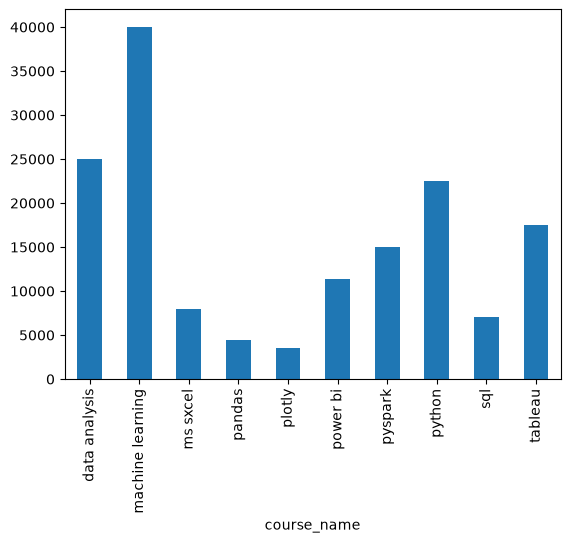

In [91]:
# plot bar chart for revenue/course
regs.merge(courses , on='course_id').drop(columns=['student_id' , 'course_id']).groupby('course_name').price.sum().plot(kind='bar')

In [92]:
# find students who enrolled in boyh months Nov and Dec 
month_2[month_2.student_id.isin(month_1.student_id)].merge(std , on='student_id').name.unique()

<StringArray>
[    'Parveen Bhalla',       'Elias Dodiya',       'Tarun Thaker',
       'Yasmin Palan', 'David Mukhopadhyay',    'Fardeen Mahabir',
      'Kailash Harjo',         'Yash Sethi',     'Chhavi Lachman']
Length: 9, dtype: str

In [93]:
# OR (more easy)
common_ids = np.intersect1d(month_2['student_id'], month_1['student_id'])
std[std.student_id.isin(common_ids)].reset_index().name

0         Kailash Harjo
1        Parveen Bhalla
2          Tarun Thaker
3    David Mukhopadhyay
4          Elias Dodiya
5          Yasmin Palan
6       Fardeen Mahabir
7            Yash Sethi
8        Chhavi Lachman
Name: name, dtype: str

In [94]:
# find courses that got no enrollment
temp = courses.merge(regs , how='left' , on='course_id')
temp[temp.student_id.isna()].course_name

53    Numpy
54      C++
Name: course_name, dtype: str

In [95]:
# FIND STUDENTS WHO DID'T ENROLL IN ANY COURSE
ids = std.student_id
np.setdiff1d(ids , regs.student_id).size

10

In [96]:
# make a table with student_name and in other column his/her partner name
std.merge(std , how='inner' , left_on='student_id' , right_on='partner')[['name_x' , 'name_y']].rename(columns={'name_x' : 'student_name' , 'name_y' : 'partner'})


,student_name,partner
0,Kailash Harjo,Esha Butala
1,Yasmin Palan,Radhika Suri
2,Parveen Bhalla,Parveen Bhalla
3,Marlo Dugal,Nitika Chatterjee
4,Kusum Bahri,Radheshyam Dey
5,Lakshmi Contractor,Kusum Bahri
6,Shashank D’Alia,Hamza
7,Radheshyam Dey,Aayushman Sant
8,Nitika Chatterjee,Tarun Thaker
9,Aayushman Sant,Lakshmi Contractor


In [97]:
#   OR
# Create mapping from ID to Name
id_to_name = std.set_index('student_id')['name'].to_dict()

# Construct final DataFrame
result = pd.DataFrame({
    'student_name': std['name'],
    'partner_name': std['partner'].map(id_to_name)
})
result

,student_name,partner_name
0,Kailash Harjo,Chhavi Lachman
1,Esha Butala,Kailash Harjo
2,Parveen Bhalla,Parveen Bhalla
3,Marlo Dugal,Pranab Natarajan
4,Kusum Bahri,Lakshmi Contractor
5,Lakshmi Contractor,Aayushman Sant
6,Tarun Thaker,Nitika Chatterjee
7,Radheshyam Dey,Kusum Bahri
8,Nitika Chatterjee,Marlo Dugal
9,Aayushman Sant,Radheshyam Dey


In [98]:
# FIND TOP3 STUDENTS WITH MOST ENROLLMENTS
# we use groupby here on the basis of student id and name because 
# if we simply filter on names two students may have same name
std.merge(regs, on='student_id').groupby(['student_id' , 'name']).name.count().sort_values(ascending=False).head(3)

student_id  name            
23          Chhavi Lachman      6
7           Tarun Thaker        5
14          Pranab Natarajan    4
Name: name, dtype: int64

In [99]:
# find top 3 students who have spent more amount on buying courses
std.merge(regs , on='student_id').merge(courses , on='course_id').groupby(['student_id' ,'name']).price.sum().sort_values(ascending=False).head(3)

student_id  name            
23          Chhavi Lachman      22594
14          Pranab Natarajan    15096
19          Qabeel Raman        13498
Name: price, dtype: int64

In [100]:
# other merge syntax
pd.merge(left=std , right=regs , on='student_id')
pd.merge(std ,regs , on='student_id') # same

,student_id,name,partner,course_id
0,1,Kailash Harjo,23,1
1,1,Kailash Harjo,23,6
2,1,Kailash Harjo,23,10
3,1,Kailash Harjo,23,9
4,2,Esha Butala,1,5
5,3,Parveen Bhalla,3,3
6,3,Parveen Bhalla,3,5
7,7,Tarun Thaker,9,8
8,7,Tarun Thaker,9,10
9,7,Tarun Thaker,9,7


**Find top3 stadiums with most no. of sixes/matches ratio in ipl**

In [101]:
matches.head(2)

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN


In [102]:
deliveries.head(3)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN


In [103]:
stadiums = matches.merge(deliveries , left_on='id' , right_on= 'match_id')

In [122]:
sixes = stadiums[stadiums.batsman_runs == 6].groupby('venue').batsman_runs.count()

In [124]:
no_of_matches = matches['venue'].value_counts()

In [125]:
(sixes/no_of_matches).sort_values(ascending=False).head(3)

venue
Holkar Cricket Stadium     17.600000
M Chinnaswamy Stadium      13.227273
Sharjah Cricket Stadium    12.666667
dtype: float64

In [126]:
s1 = pd.Series([8,6,4,2] , index=[3,2,1,0])
s2 = pd.Series([1,2,6,2])

In [127]:
s1/s2

0    2.0
1    2.0
2    1.0
3    4.0
dtype: float64

**find orange cap holder of all seasons in ipl**(most scorer of a season)

In [129]:
deliveries.head(3)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN


In [132]:
temp_df = matches.merge(deliveries , left_on='id' , right_on='match_id').groupby(['season' ,'batsman'])

In [146]:
season = temp_df.batsman_runs.sum().reset_index().sort_values(['season' , 'batsman_runs'] , ascending=[True,False]).groupby('season')

In [147]:
season.first()

,batsman,batsman_runs
season,,
2008,SE Marsh,616
2009,ML Hayden,572
2010,SR Tendulkar,618
2011,CH Gayle,608
2012,CH Gayle,733
2013,MEK Hussey,733
2014,RV Uthappa,660
2015,DA Warner,562
2016,V Kohli,973


In [149]:
len(month_1)

25